# 03 — Final analysis

Run all cells with Internet access on Kaggle, Colab, or local Jupyter. The notebook downloads the public team repository when needed and installs its single `requirements.txt`. A CPU is sufficient: pretrained weights, the full dataset, and a GPU are not required because the repository includes saved rankings and the images used in the three diagnostic cases.

Source tables: `results/02_second_models` (all four models). Historical diagnostic rankings are stored in `results/final_analysis_evidence` and checked against the manifest and all five current test metrics for each model. Runtime values come exclusively from the Tesla T4 run of 7 November 2026.

The analysis uses three scripts and the shared `src/` modules. It creates three CSV files, one JSON, and five PNG files in `results/03_final_analysis/`. A ZIP containing those nine files and the split manifest is saved **next to the repository directory** as `final_analysis_results.zip`.

In [1]:
from pathlib import Path
import os
import shlex
import subprocess
import sys

REPOSITORY_URL = "https://github.com/kite121/Visual_retrieval_system.git"
BRANCH = "main"


def run(command, cwd=None):
    command = [str(part) for part in command]
    print("$", shlex.join(command), flush=True)
    subprocess.run(command, cwd=cwd, check=True)


start_dir = Path.cwd().resolve()
local_repositories = [
    parent for parent in (start_dir, *start_dir.parents)
    if (parent / ".git").exists()
    and (parent / "scripts" / "run_evaluation.py").is_file()
]
if local_repositories:
    ROOT = local_repositories[0]
    print("Using the existing repository checkout:", ROOT)
else:
    ROOT = start_dir / "Visual_retrieval_system"
    if not ROOT.exists():
        run(["git", "clone", "--branch", BRANCH, "--depth", "1", REPOSITORY_URL, ROOT])
    else:
        if not (ROOT / ".git").exists():
            raise RuntimeError(f"{ROOT} exists but is not a Git checkout")
        current_branch = subprocess.check_output(
            ["git", "branch", "--show-current"], cwd=ROOT, text=True,
        ).strip()
        if current_branch != BRANCH:
            raise RuntimeError(f"Switch {ROOT} to {BRANCH} before running this notebook")
        run(["git", "pull", "--ff-only", "origin", BRANCH], cwd=ROOT)

os.chdir(ROOT)
SOURCE_COMMIT = subprocess.check_output(
    ["git", "rev-parse", "HEAD"], cwd=ROOT, text=True,
).strip()
print("Repository:", ROOT)
print("Source commit:", SOURCE_COMMIT)

required = [
    "requirements.txt", "configs/split_manifest.csv",
    "scripts/build_final_results.py", "scripts/generate_final_figures.py",
    "scripts/export_failure_cases.py", "results/final_analysis_evidence/selection.json",
    *[f"results/02_second_models/{name}" for name in (
        "metrics_validation.csv", "metrics_test.csv", "runtime_summary.csv", "run_metadata.json",
    )],
]
missing = [name for name in required if not (ROOT / name).is_file()]
if missing:
    raise FileNotFoundError(
        "The checkout is missing final-analysis inputs: " + ", ".join(missing)
        + ". Update this checkout to the current main branch."
    )

$ git clone --branch main --depth 1 https://github.com/kite121/Visual_retrieval_system.git /private/tmp/p09-notebook03-clone-h51u0vvb/fresh-session/Visual_retrieval_system


Cloning into '/private/tmp/p09-notebook03-clone-h51u0vvb/fresh-session/Visual_retrieval_system'...


Repository: /private/tmp/p09-notebook03-clone-h51u0vvb/fresh-session/Visual_retrieval_system
Source commit: 8d431d951c98a9422fda4e6fd6112491368659d5


## Environment setup

Install dependencies from the repository root. Existing compatible installations are retained. All later cells import and execute the repository scripts; this notebook contains no duplicated implementation of the analysis.

In [2]:
run([
    sys.executable, "-m", "pip", "install", "--disable-pip-version-check",
    "-q", "-r", ROOT / "requirements.txt",
])

from IPython.display import FileLink, Image, display
sys.path.insert(0, str(ROOT / "scripts"))
sys.path.insert(0, str(ROOT))
from build_final_results import build
from generate_final_figures import generate
from export_failure_cases import export

SOURCE = ROOT / "results/02_second_models"
OUTPUT = ROOT / "results/03_final_analysis"
EVIDENCE = ROOT / "results/final_analysis_evidence"
print("Analysis source:", SOURCE)
print("Output directory:", OUTPUT)

$ /Users/kite/Documents/ChatGPT/CV/Visual_retrieval_system/.venv/bin/python -m pip install --disable-pip-version-check -q -r /private/tmp/p09-notebook03-clone-h51u0vvb/fresh-session/Visual_retrieval_system/requirements.txt


Matplotlib is building the font cache; this may take a moment.


Analysis source: /private/tmp/p09-notebook03-clone-h51u0vvb/fresh-session/Visual_retrieval_system/results/02_second_models
Output directory: /private/tmp/p09-notebook03-clone-h51u0vvb/fresh-session/Visual_retrieval_system/results/03_final_analysis


## 1. Таблицы и происхождение данных

Сохраняются исходные имена столбцов нового формата. Проверяются SHA-256 манифеста, размеры выборок, четыре pretrained-модели, диапазоны метрик и статистики трёх повторов. Данные `01_first_models` не добавляются повторно: они уже включены в `02_second_models`.

In [3]:
quality, runtime = build(SOURCE, OUTPUT)
display(quality)
display(runtime)

,model_id,model,split,precision_at_5,recall_at_5,precision_at_10,recall_at_10,hit_at_5
0,dino_vit_s16,DINO ViT-S/16,validation,0.860870,0.086574,0.827772,0.166496,0.982609
1,deit_vit_s16_supervised,DeiT-S/16 (supervised),validation,0.888261,0.089343,0.869185,0.174874,0.985870
2,dinov2_vit_b14,DINOv2 ViT-B/14,validation,0.911196,0.091641,0.888370,0.178694,0.984783
3,deit_vit_b16_supervised,DeiT-B/16 (supervised),validation,0.893913,0.089911,0.876685,0.176366,0.987500
4,dino_vit_s16,DINO ViT-S/16,test,0.841592,0.084661,0.815617,0.164092,0.974652
5,deit_vit_s16_supervised,DeiT-S/16 (supervised),test,0.866503,0.087161,0.852739,0.171566,0.969201
6,dinov2_vit_b14,DINOv2 ViT-B/14,test,0.906351,0.091158,0.888117,0.178651,0.982011
7,deit_vit_b16_supervised,DeiT-B/16 (supervised),test,0.875170,0.088028,0.860425,0.173113,0.967839


,model_id,repeats,gallery_build_seconds_median,gallery_build_seconds_min,gallery_build_seconds_max,embed_median_ms,embed_min_ms,embed_max_ms,search_median_ms,search_min_ms,search_max_ms,preprocess_median_ms,preprocess_min_ms,preprocess_max_ms,n_queries,search_k,device,gpu,batch_size,num_workers
0,dino_vit_s16,3,8.141885,8.137353,8.318728,6.253224,6.198142,6.297399,0.224191,0.221470,0.224683,5.595587,5.529123,5.603112,200,5,cuda,Tesla T4,64,2
1,deit_vit_s16_supervised,3,7.829881,7.760553,7.983455,5.101291,5.027966,5.325260,0.226039,0.222298,0.226804,5.583073,5.539011,5.707585,200,5,cuda,Tesla T4,64,2
2,dinov2_vit_b14,3,28.157744,28.150891,28.678650,18.637943,18.363545,18.796024,0.251709,0.250039,0.257754,5.637853,5.617914,5.663895,200,5,cuda,Tesla T4,64,2
3,deit_vit_b16_supervised,3,20.617534,20.409394,20.694197,12.469967,12.428803,12.502859,0.252773,0.246764,0.254649,5.664468,5.613475,5.702813,200,5,cuda,Tesla T4,64,2


## 2. Сравнительные графики

Test Precision@5 и время. Gallery build показано в секундах, компоненты запроса — в миллисекундах. Погрешности показывают min/max повторов, а не доверительные интервалы. Медианы компонентов не складываются в якобы измеренную общую задержку.

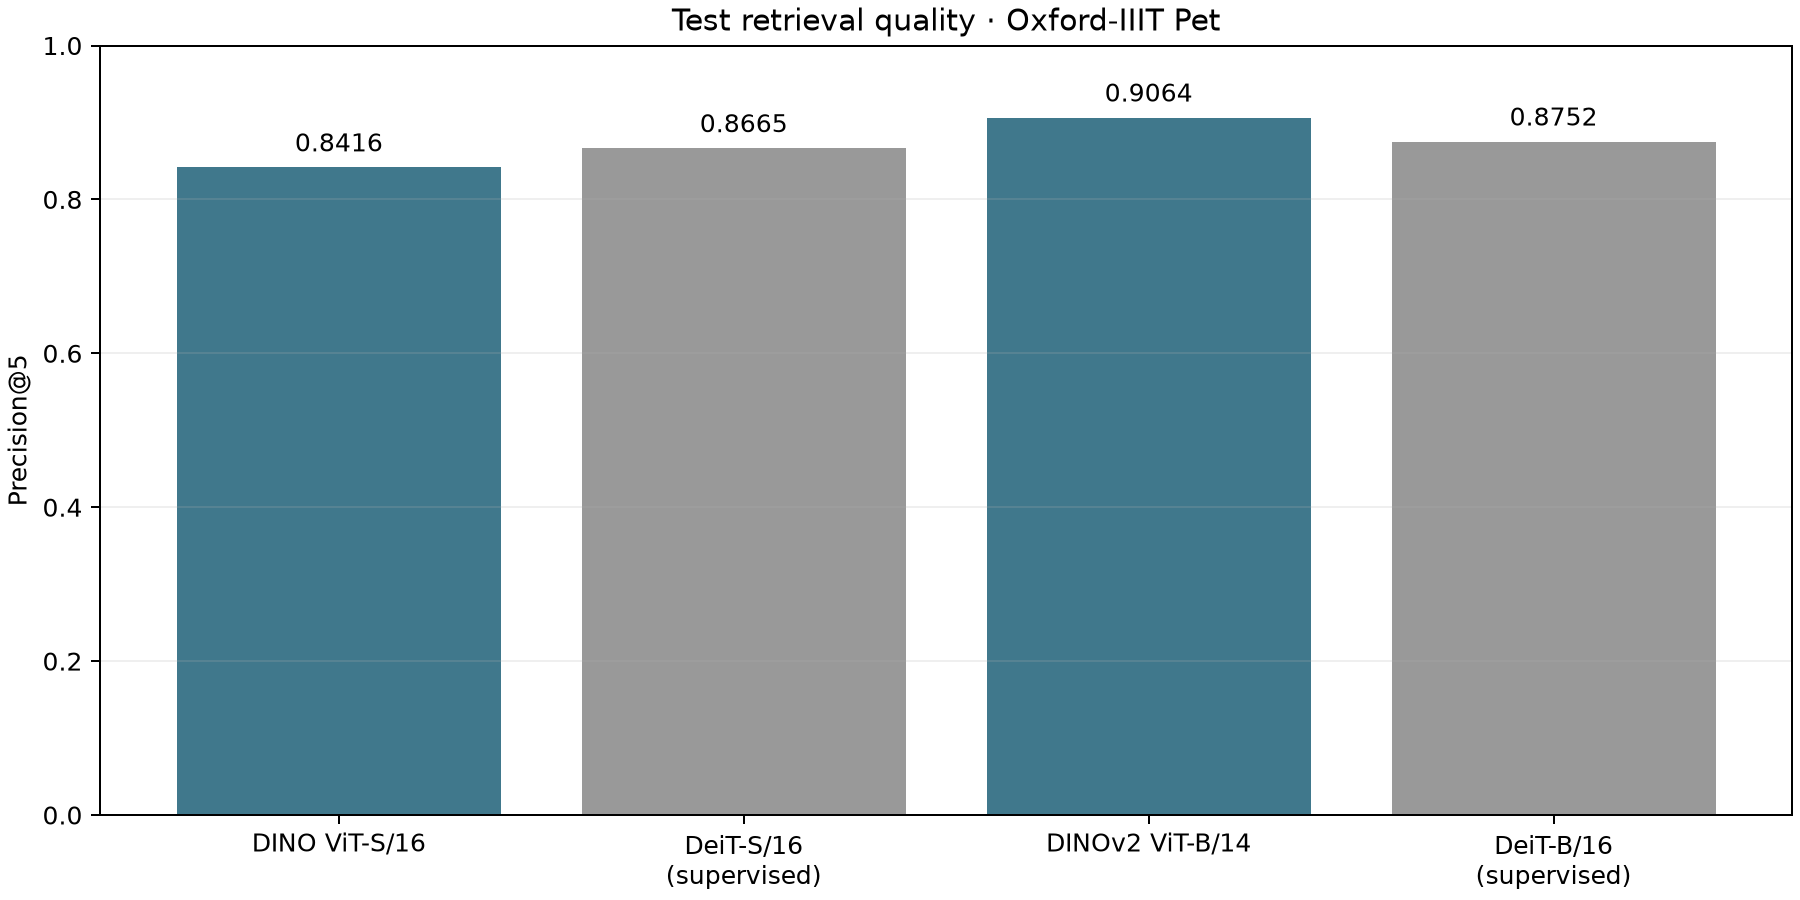

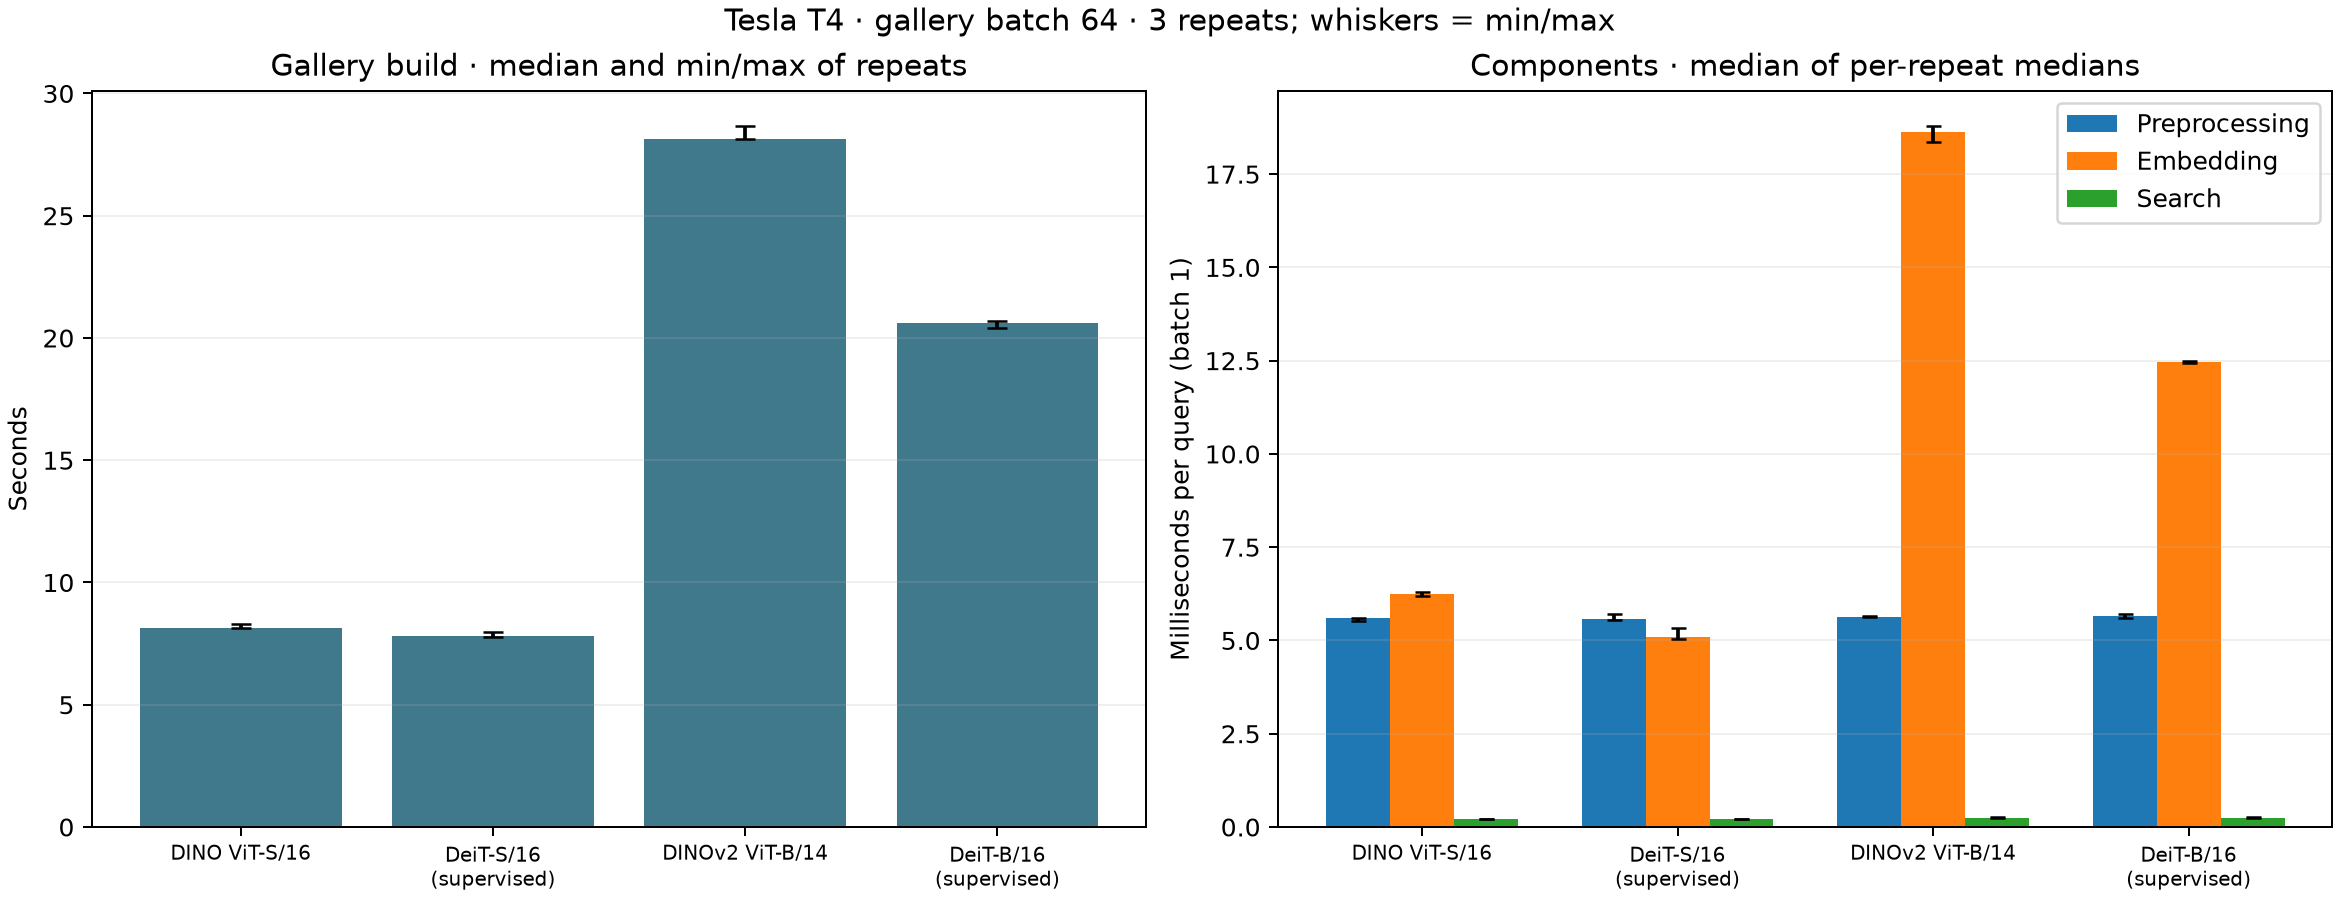

In [4]:
from IPython.display import Image, display
generate(OUTPUT)
display(Image(filename=str(OUTPUT / "figures/precision_at_5_comparison.png")))
display(Image(filename=str(OUTPUT / "figures/runtime_comparison.png")))

## 3. Три диагностических ошибки

Используются настоящие query и top-5 с сохранёнными cosine scores. Проверяются все test-рейтинги четырёх моделей и соответствие метрик актуальным таблицам (допуск 1e-6). Гипотезы о причинах отделены от наблюдений. Каждый пример включает query и пять найденных изображений.

Для собственных артефактов можно передать `artifacts=ROOT / "artifacts"` и `root=ROOT / "data"` в `export`. Там должны быть `runs/<model>/evaluation.json` и рейтинги `topk_test.npz` либо `embeddings/<model>/{gallery,test}.npz` с метаданными. При отсутствии рейтингов используется существующий `GalleryIndex`, без повторного извлечения эмбеддингов.

,model_id,split,query_id,query_breed,precision_at_5,hit_at_5,observation,explanation,figure
0,dino_vit_s16,test,Abyssinian_21,Abyssinian,0.0,0.0,Observed pattern: the query is a sleeping cat ...,A plausible explanation is reduced access to b...,figures/failure_case_01.png
1,dinov2_vit_b14,test,Siamese_228,Siamese,0.0,0.0,Observed pattern: the Siamese-labeled query ha...,This case illustrates a fine-grained breed bou...,figures/failure_case_02.png
2,deit_vit_b16_supervised,test,leonberger_73,Leonberger,0.0,0.0,Observed pattern: a Leonberger-labeled dog is ...,A plausible confusion is that shared coat text...,figures/failure_case_03.png


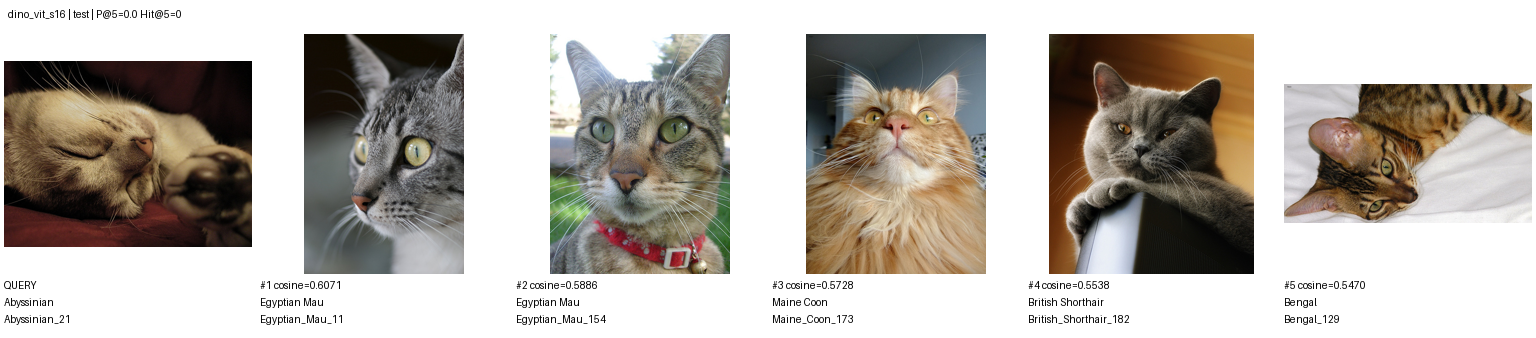

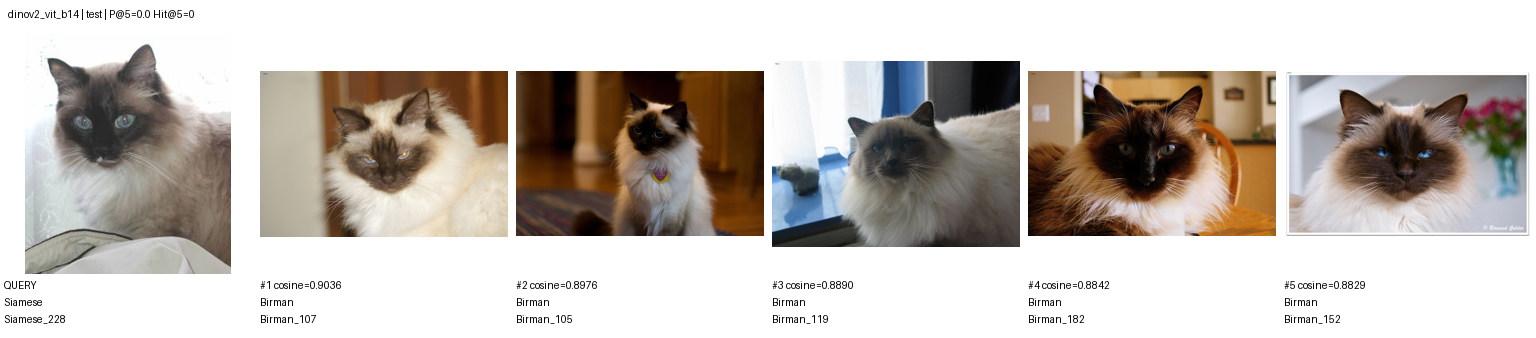

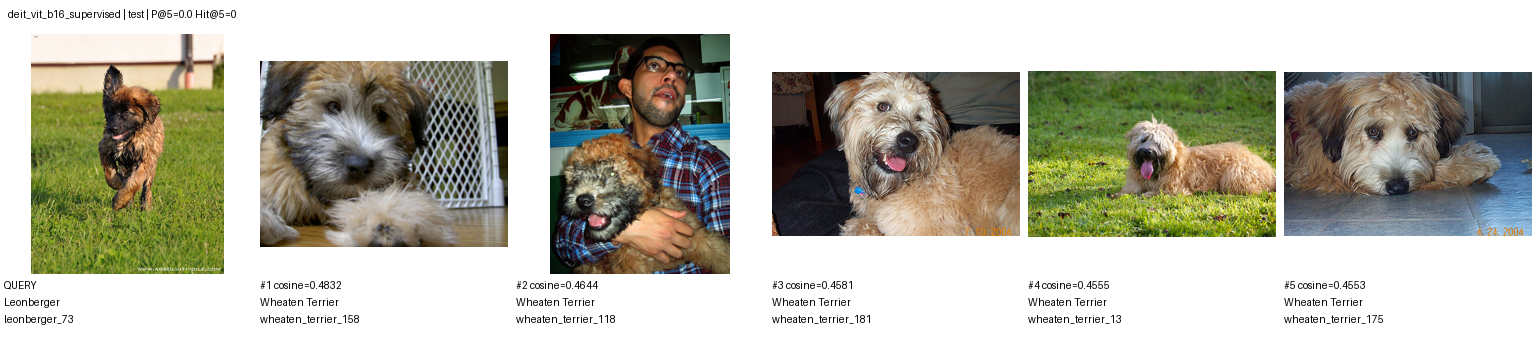

In [5]:
failures = export(OUTPUT, EVIDENCE)
display(failures.drop(columns="hits_json"))
for filename in failures.figure:
    display(Image(filename=str(OUTPUT / filename)))

## 4. Проверка комплекта

В запросе перечислены девять файлов: три CSV, один JSON и пять PNG. Notebook можно запускать повторно: вычисляемые файлы перезаписываются, исходные результаты остаются источником анализа.

In [6]:
import json
expected = ["final_quality_metrics.csv", "runtime_summary.csv", "failure_cases.csv", "run_metadata.json",
            "figures/precision_at_5_comparison.png", "figures/runtime_comparison.png",
            *[f"figures/failure_case_{i:02d}.png" for i in range(1, 4)]]
assert all((OUTPUT / name).is_file() for name in expected)
assert len(quality) == 8 and len(runtime) == 4 and len(failures) == 3
metadata = json.loads((OUTPUT / "run_metadata.json").read_text(encoding="utf-8"))
assert metadata["failure_cases"]["status"] == "complete"
for name in expected:
    print(f"{name}: {(OUTPUT / name).stat().st_size:,} bytes")

final_quality_metrics.csv: 1,211 bytes
runtime_summary.csv: 1,362 bytes
failure_cases.csv: 4,928 bytes
run_metadata.json: 21,647 bytes
figures/precision_at_5_comparison.png: 52,006 bytes
figures/runtime_comparison.png: 97,943 bytes
figures/failure_case_01.png: 483,783 bytes
figures/failure_case_02.png: 382,455 bytes
figures/failure_case_03.png: 565,558 bytes


## Download the results

The ZIP is written beside the repository, matching notebooks 01 and 02. It contains only the nine final outputs and the shared split manifest; original tables, evidence, model weights, and caches are not duplicated in the archive.

In [7]:
import zipfile

metadata["analysis_source_commit"] = SOURCE_COMMIT
(OUTPUT / "run_metadata.json").write_text(
    json.dumps(metadata, ensure_ascii=False, indent=2, allow_nan=False) + "\n",
    encoding="utf-8",
)
archive_path = ROOT.parent / "final_analysis_results.zip"
files = [OUTPUT / name for name in expected] + [ROOT / "configs/split_manifest.csv"]
with zipfile.ZipFile(archive_path, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    for path in files:
        archive.write(path, path.relative_to(ROOT).as_posix())
with zipfile.ZipFile(archive_path) as archive:
    assert archive.testzip() is None
    assert len(archive.namelist()) == 10
print("Created:", archive_path)
display(FileLink(os.path.relpath(archive_path, Path.cwd())))

Created: /private/tmp/p09-notebook03-clone-h51u0vvb/fresh-session/final_analysis_results.zip


/private/tmp/p09-notebook03-clone-h51u0vvb/fresh-session/final_analysis_results.zip